from keras.datasets import mnist
from keras.layers import Input, Dense
from keras.models import Model, Sequential
from keras.utils import np_utils
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from livelossplot import PlotLossesKeras

%matplotlib inline

In [1]:
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split

import keras
from keras.models import Sequential
from keras.layers import Dense
import tensorflow as tf
from livelossplot import PlotLossesKeras

Using TensorFlow backend.
/home/eduarda/anaconda3/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:516: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
/home/eduarda/anaconda3/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:517: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
/home/eduarda/anaconda3/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:518: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
/home/eduarda/anaconda3/lib/python3.7/site-packages/t

# Upload and Preprocessing

https://www.tensorflow.org/tutorials/load_data/csv

## Upload

In [3]:
import pandas as pd

hrv_data_path = "/home/eduarda/Desktop/HRVdata/ProcessedECGData.csv"
NUMERIC_FEATURES = ['rr_mean', 'hr_mean', 'sdnn', 'rmssd', 'pnn50']

data = pd.read_csv(hrv_data_path)

print(data)

                            file  label   rr_mean    hr_mean        sdnn  \
0     S2_baseline_ECG_values.csv      0  0.932707  64.833482   84.423701   
1     S2_baseline_ECG_values.csv      0  0.990232  61.760423  138.585109   
2     S2_baseline_ECG_values.csv      0  1.102083  55.163224  123.660528   
3     S2_baseline_ECG_values.csv      0  1.058913  57.268985  106.917941   
4     S2_baseline_ECG_values.csv      0  1.177570  51.152315   68.924331   
...                          ...    ...       ...        ...         ...   
3775             S4_stress_T.csv      1  1.024887  59.481705  129.949415   
3776             S4_stress_T.csv      1  1.028602  59.024902  111.326466   
3777             S4_stress_T.csv      1  1.037167  59.286641  183.821642   
3778             S4_stress_T.csv      1  0.987644  63.117200  238.028070   
3779             S4_stress_T.csv      1  0.852225  72.542127  150.410813   

           rmssd      pnn50  
0      51.336796  26.666667  
1      88.818233  46.428571

In [4]:
x_features_df = data.iloc[:,2:7]
#print(x)

y_label_df = data.iloc[:,1]
#print(y)

x_features = x_features_df.to_numpy()
y_label = y_label_df.to_numpy()
print(x_features)
print(y_label)

[[  0.93270673  64.83348184  84.423701    51.33679642  26.66666667]
 [  0.9902319   61.76042273 138.58510927  88.81823333  46.42857143]
 [  1.10208298  55.16322367 123.66052787 101.97764461  48.        ]
 ...
 [  1.03716667  59.2866409  183.82164185 253.29945792  80.76923077]
 [  0.98764395  63.11719969 238.02806992 312.86618545  57.14285714]
 [  0.85222512  72.54212664 150.41081296 170.15305053  51.51515152]]
[0 0 0 ... 1 1 1]


## Data Normalization

In [5]:
desc = pd.read_csv(hrv_data_path)[NUMERIC_FEATURES].describe()
desc

mean = np.array(desc.T['mean'])
std = np.array(desc.T['std'])

In [6]:
def normalize_numeric_data(data, mean, std):
  # Center the data
  return (data-mean)/std

In [7]:
x_features_normal = normalize_numeric_data(x_features, mean, std)
print(x_features_normal)

[[ 0.85617718 -0.88000973 -0.24049519 -0.43431797 -0.21292861]
 [ 1.25515557 -1.06649046  0.22136651 -0.22855505  0.59714688]
 [ 2.03092308 -1.46682461  0.09409706 -0.15631346  0.66156252]
 ...
 [ 1.5806819  -1.21660558  0.60712128  0.67440222  2.00483136]
 [ 1.23720624 -0.98415792  1.06936689  1.00140738  1.03634444]
 [ 0.29797943 -0.41223034  0.32221026  0.21795101  0.80565481]]


# Deep Learning

## Splitting the data

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x_features_normal, y_label, test_size = 0.2)

## Building the model

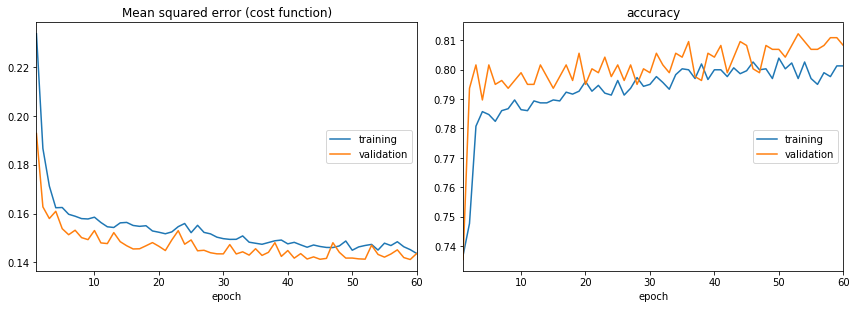



Test Loss 0.1436161946051966, Test Accuracy 0.8082010746002197


In [12]:
def create_model():
    model = Sequential()
    model.add(Dense(128, activation='relu'))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1))
    
    model.compile(
        loss='mean_squared_error',
        optimizer='adam',
        metrics=['accuracy'])

    
    return model

model = create_model()

history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=60, batch_size=300, verbose=0, callbacks=[PlotLossesKeras()])

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print('\n\nTest Loss {}, Test Accuracy {}'.format(test_loss, test_accuracy))